In [13]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/dataset/test/rottenbanana/saltandpepper_Screen Shot 2018-06-12 at 8.53.54 PM.png
/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/dataset/test/rottenbanana/Screen Shot 2018-06-12 at 9.27.26 PM.png
/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/dataset/test/rottenbanana/rotated_by_45_Screen Shot 2018-06-12 at 8.58.13 PM.png
/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/dataset/test/rottenbanana/rotated_by_75_Screen Shot 2018-06-12 at 8.47.41 PM.png
/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/dataset/test/rottenbanana/rotated_by_75_Screen Shot 2018-06-12 at 8.56.30 PM.png
/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/dataset/test/rottenbanana/saltandpepper_Screen Shot 2018-06-12 at 9.11.17 PM.png
/kaggle/input/datasets/sriramr/fruit

In [14]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    print(dirname)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/sriramr
/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification
/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset
/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/dataset
/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/dataset/test
/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/dataset/test/rottenbanana
/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/dataset/test/freshoranges
/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/dataset/test/rottenoranges
/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/dataset/test/freshbanana
/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/dataset/test/rottenapples
/kaggle/input/datasets/sriramr/fruits-fresh-and-rot

In [15]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

import os

# Reproducibility: set seeds before creating datasets/models
import random
SEED = 123
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


In [16]:
import os

print("Available datasets:")
print(os.listdir("/kaggle/input"))

for root, dirs, files in os.walk("/kaggle/input"):
    if "freshapples" in dirs:
        print("Found fruit classes at:", root)

Available datasets:
['datasets']
Found fruit classes at: /kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/dataset/test
Found fruit classes at: /kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/dataset/train
Found fruit classes at: /kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/test
Found fruit classes at: /kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/train


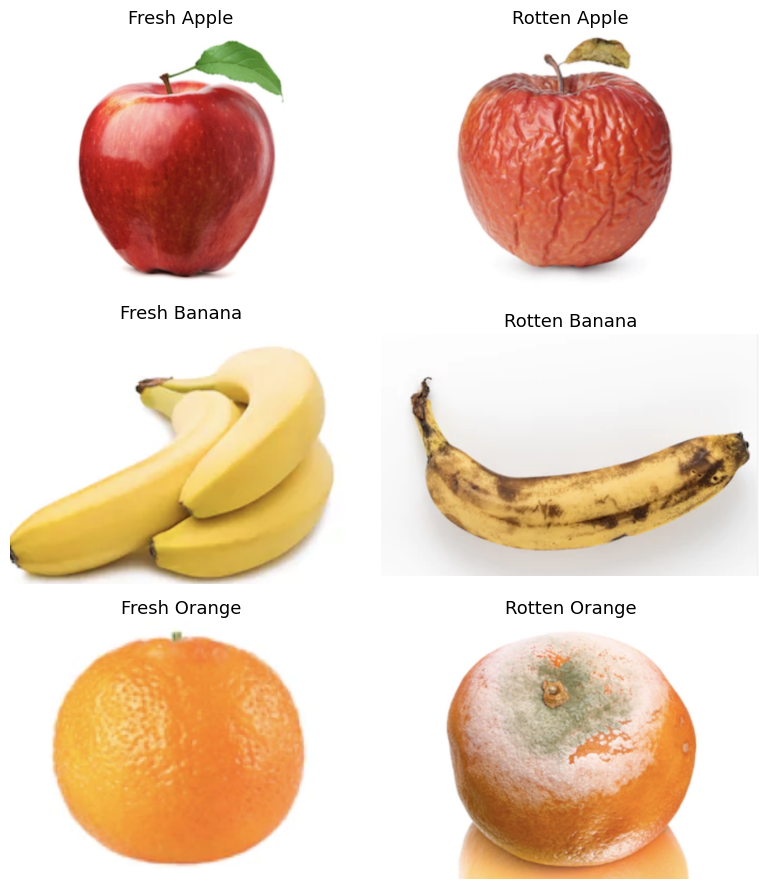

Both images saved successfully!


In [17]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# Correct dataset path
train_dir = "/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/train"

# Six fruit categories
classes = [
    "freshapples",
    "rottenapples",
    "freshbanana",
    "rottenbanana",
    "freshoranges",
    "rottenoranges"
]

titles = [
    "Fresh Apple",
    "Rotten Apple",
    "Fresh Banana",
    "Rotten Banana",
    "Fresh Orange",
    "Rotten Orange"
]

# Create a 3-row, 2-column figure
fig, axes = plt.subplots(3, 2, figsize=(8, 9))

for ax, class_name, title in zip(axes.flat, classes, titles):

    folder = os.path.join(train_dir, class_name)

    image_name = next(
        f for f in sorted(os.listdir(folder))
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    )

    image = Image.open(os.path.join(folder, image_name))

    ax.imshow(image)
    ax.set_title(title, fontsize=13)
    ax.axis("off")

plt.tight_layout()

# Save as PDF and PNG
plt.savefig(
    "/kaggle/working/dataset_samples.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "/kaggle/working/dataset_samples.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

print("Both images saved successfully!")

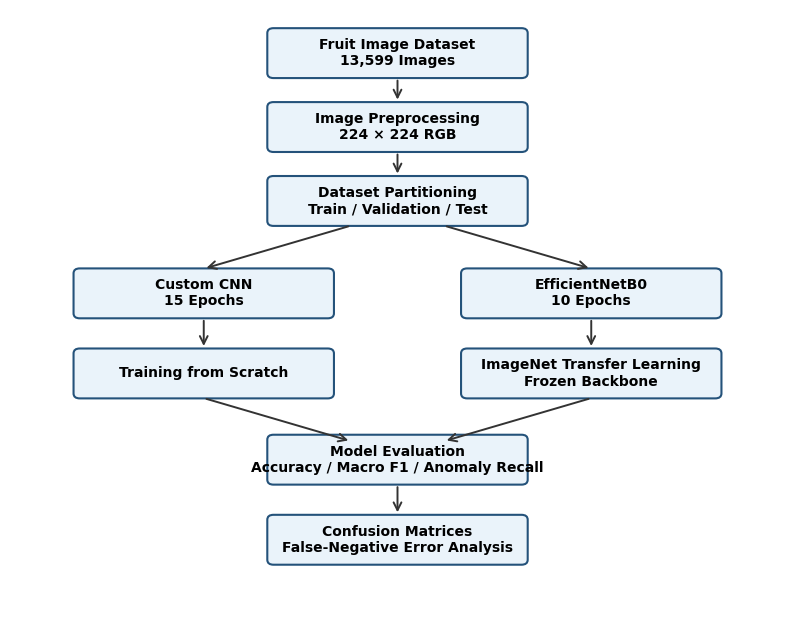

Figure 2 generated successfully!


In [18]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(10, 8))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis("off")

def box(x, y, text, width=3.2, height=0.65):
    rect = FancyBboxPatch(
        (x - width/2, y - height/2),
        width, height,
        boxstyle="round,pad=0.08",
        linewidth=1.5,
        edgecolor="#24527A",
        facecolor="#EAF3FA"
    )
    ax.add_patch(rect)
    ax.text(x, y, text, ha="center", va="center",
            fontsize=10, fontweight="bold")

def arrow(x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="->",
        mutation_scale=14,
        linewidth=1.4,
        color="#333333"
    ))

box(5, 9.3, "Fruit Image Dataset\n13,599 Images")
box(5, 8.1, "Image Preprocessing\n224 × 224 RGB")
box(5, 6.9, "Dataset Partitioning\nTrain / Validation / Test")

box(2.5, 5.4, "Custom CNN\n15 Epochs")
box(7.5, 5.4, "EfficientNetB0\n10 Epochs")

box(2.5, 4.1, "Training from Scratch")
box(7.5, 4.1, "ImageNet Transfer Learning\nFrozen Backbone")

box(5, 2.7, "Model Evaluation\nAccuracy / Macro F1 / Anomaly Recall")
box(5, 1.4, "Confusion Matrices\nFalse-Negative Error Analysis")

arrow(5, 8.9, 5, 8.5)
arrow(5, 7.7, 5, 7.3)

arrow(4.4, 6.5, 2.5, 5.8)
arrow(5.6, 6.5, 7.5, 5.8)

arrow(2.5, 5.0, 2.5, 4.5)
arrow(7.5, 5.0, 7.5, 4.5)

arrow(2.5, 3.7, 4.4, 3.0)
arrow(7.5, 3.7, 5.6, 3.0)

arrow(5, 2.3, 5, 1.8)

plt.savefig(
    "/kaggle/working/methodology_workflow.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "/kaggle/working/methodology_workflow.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 2 generated successfully!")

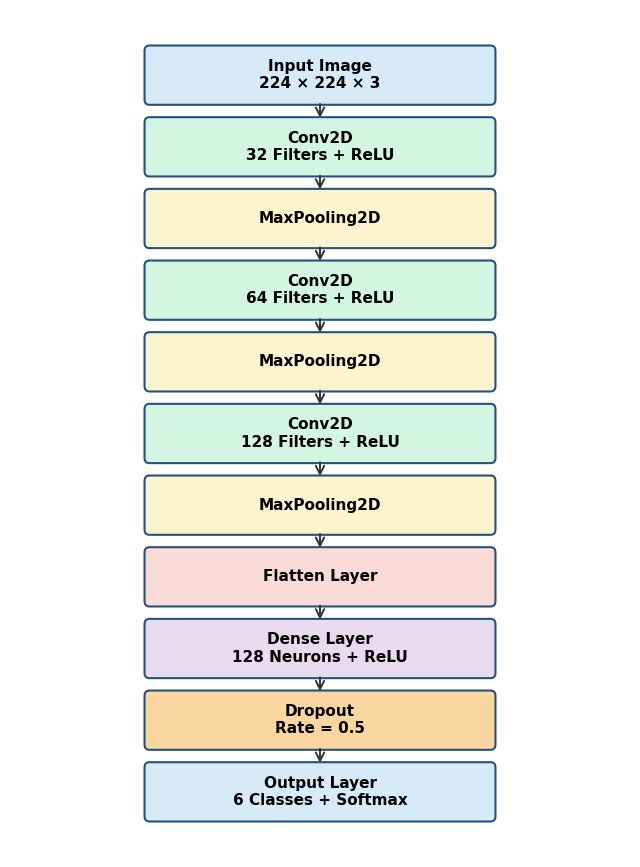

Custom CNN architecture figure generated successfully!


In [19]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(8, 11))
ax.set_xlim(0, 10)
ax.set_ylim(0, 13)
ax.axis("off")

def add_box(x, y, text, color="#EAF3FA", width=5.5):
    height = 0.75

    rect = FancyBboxPatch(
        (x - width/2, y - height/2),
        width,
        height,
        boxstyle="round,pad=0.08",
        linewidth=1.5,
        edgecolor="#24527A",
        facecolor=color
    )

    ax.add_patch(rect)
    ax.text(
        x, y, text,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

def add_arrow(y1, y2):
    arrow = FancyArrowPatch(
        (5, y1),
        (5, y2),
        arrowstyle="->",
        mutation_scale=15,
        linewidth=1.4,
        color="#333333"
    )
    ax.add_patch(arrow)

layers = [
    ("Input Image\n224 × 224 × 3", "#D6EAF8"),
    ("Conv2D\n32 Filters + ReLU", "#D5F5E3"),
    ("MaxPooling2D", "#FCF3CF"),
    ("Conv2D\n64 Filters + ReLU", "#D5F5E3"),
    ("MaxPooling2D", "#FCF3CF"),
    ("Conv2D\n128 Filters + ReLU", "#D5F5E3"),
    ("MaxPooling2D", "#FCF3CF"),
    ("Flatten Layer", "#FADBD8"),
    ("Dense Layer\n128 Neurons + ReLU", "#E8DAEF"),
    ("Dropout\nRate = 0.5", "#FAD7A0"),
    ("Output Layer\n6 Classes + Softmax", "#D6EAF8")
]

y_positions = [
    12, 10.9, 9.8, 8.7, 7.6,
    6.5, 5.4, 4.3, 3.2, 2.1, 1.0
]

for i, ((label, color), y) in enumerate(zip(layers, y_positions)):
    add_box(5, y, label, color)

    if i < len(y_positions) - 1:
        add_arrow(y - 0.4, y_positions[i+1] + 0.4)

plt.savefig(
    "/kaggle/working/custom_cnn_architecture.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "/kaggle/working/custom_cnn_architecture.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Custom CNN architecture figure generated successfully!")

In [20]:
# Check all variables that may contain training history

for name, value in list(globals().items()):
    if any(word in name.lower() for word in
           ["history", "hist", "cnn", "efficient", "model"]):
        print(name, ":", type(value).__name__)

histories : dict


In [21]:
import tensorflow as tf

print("Available trained models:")

for name, value in list(globals().items()):
    if isinstance(value, tf.keras.Model):
        print(name, "- Model found")

Available trained models:


In [22]:
import os

print("Saved model and training history files:")

for root, dirs, files in os.walk("/kaggle/working"):
    for file in files:
        if file.endswith((".csv", ".json", ".pkl", ".keras", ".h5")):
            print(os.path.join(root, file))

Saved model and training history files:


In [23]:
# Locate the attached dataset inside Kaggle's read-only input directory.
# This avoids hard-coding a folder name that may differ between notebooks.
import os
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123

input_root = "/kaggle/input"
dataset_candidates = []

for root, dirs, files in os.walk(input_root):
    if "train" in dirs and "test" in dirs:
        dataset_candidates.append(root)

if not dataset_candidates:
    raise FileNotFoundError(
        "Could not find a folder containing both 'train' and 'test' under /kaggle/input. "
        "In Kaggle, click Add Input and attach the fruit dataset, then rerun this cell. "
        "If your dataset uses different folder names, inspect os.walk('/kaggle/input') output."
    )

# Prefer a candidate whose path mentions fruit; otherwise use the first matching folder.
fruit_candidates = [p for p in dataset_candidates if "fruit" in p.lower()]
DATASET_PATH = fruit_candidates[0] if fruit_candidates else dataset_candidates[0]
train_path = os.path.join(DATASET_PATH, "train")
test_path = os.path.join(DATASET_PATH, "test")

print("Using dataset folder:", DATASET_PATH)
print("Train folder:", train_path)
print("Test folder:", test_path)

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="int"
)

class_names = train_ds.class_names
if test_ds.class_names != class_names:
    raise ValueError(
        f"Train/test class order differs. Train: {class_names}; test: {test_ds.class_names}"
    )

print("Class names:", class_names)
print("Number of classes:", len(class_names))

# Improve input-pipeline throughput while keeping the test order deterministic.
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)


Using dataset folder: /kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset
Train folder: /kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/train
Test folder: /kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/test
Found 10901 files belonging to 6 classes.
Using 8721 files for training.


2026-10-13 16:55:35.096119: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Found 10901 files belonging to 6 classes.
Using 2180 files for validation.
Found 2698 files belonging to 6 classes.
Class names: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']
Number of classes: 6


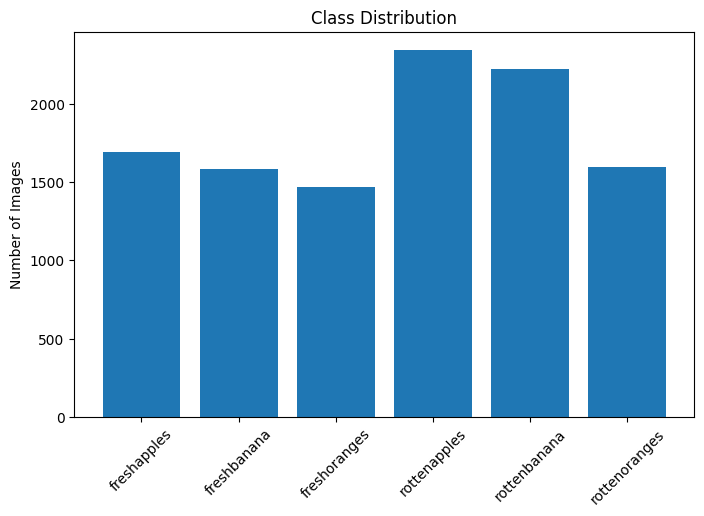

In [24]:
import os

class_counts = {}

for cls in class_names:
    class_counts[cls] = len(
        os.listdir(os.path.join(train_path, cls))
    )

plt.figure(figsize=(8,5))
plt.bar(class_counts.keys(), class_counts.values())
plt.xticks(rotation=45)
plt.title("Class Distribution")
plt.ylabel("Number of Images")
plt.show()

NameError: name 'history' is not defined

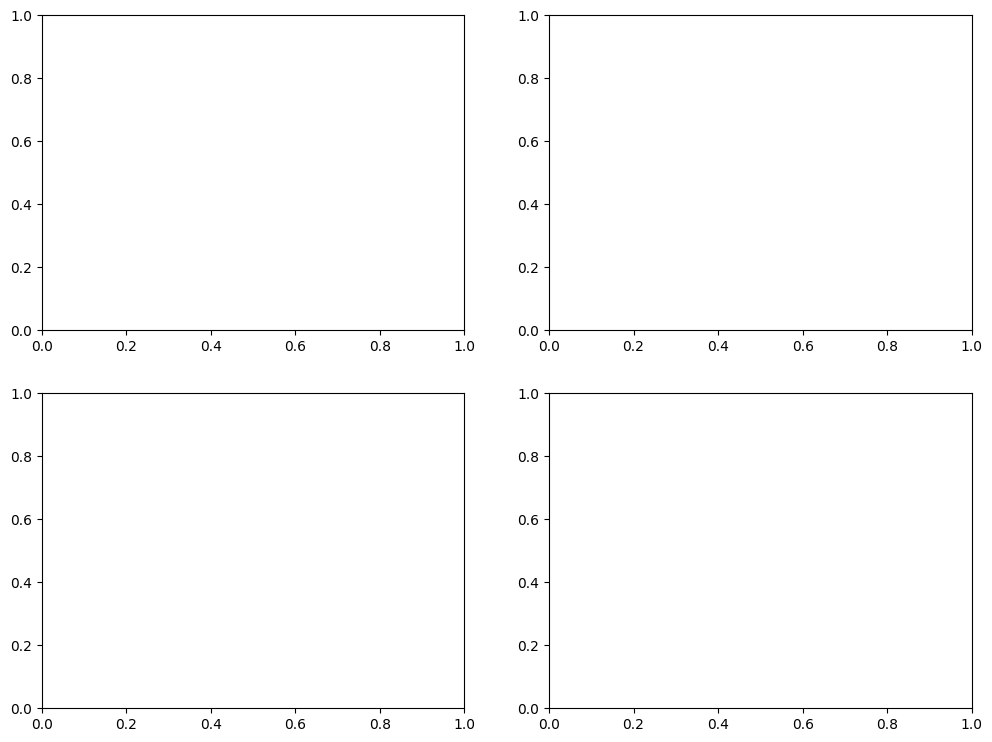

In [27]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Custom CNN accuracy
axes[0, 0].plot(history.history["accuracy"], label="Training")
axes[0, 0].plot(history.history["val_accuracy"], label="Validation")
axes[0, 0].set_title("Custom CNN - Accuracy")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Accuracy")
axes[0, 0].legend()

# Custom CNN loss
axes[0, 1].plot(history.history["loss"], label="Training")
axes[0, 1].plot(history.history["val_loss"], label="Validation")
axes[0, 1].set_title("Custom CNN - Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()

# EfficientNetB0 accuracy
axes[1, 0].plot(history_eff.history["accuracy"], label="Training")
axes[1, 0].plot(history_eff.history["val_accuracy"], label="Validation")
axes[1, 0].set_title("EfficientNetB0 - Accuracy")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Accuracy")
axes[1, 0].legend()

# EfficientNetB0 loss
axes[1, 1].plot(history_eff.history["loss"], label="Training")
axes[1, 1].plot(history_eff.history["val_loss"], label="Validation")
axes[1, 1].set_title("EfficientNetB0 - Loss")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Loss")
axes[1, 1].legend()

for ax in axes.flat:
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/training_validation_curves.pdf",
    bbox_inches="tight"
)

plt.show()

In [25]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.20.0
GPU: []


In [26]:
class_names = train_ds.class_names

print(class_names)
print("Number of Classes:", len(class_names))

AttributeError: '_PrefetchDataset' object has no attribute 'class_names'

In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2)
])

plt.figure(figsize=(10,10))

for images, _ in train_ds.take(1):
    
    first_image = images[0]
    
    for i in range(9):
        
        ax = plt.subplot(3,3,i+1)
        
        augmented_image = data_augmentation(
            tf.expand_dims(first_image, 0)
        )
        
        plt.imshow(
            augmented_image[0].numpy().astype("uint8")
        )
        
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
cnn_model = Sequential([

    layers.Input(shape=(224,224,3)),

    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.5),

    layers.Dense(6, activation='softmax')

])

cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()

In [32]:
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0

# Load pretrained EfficientNetB0
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Build EfficientNetB0 classifier
efficientnet_model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(6, activation="softmax")
])

# Compile model
efficientnet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetB0 model created successfully!")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 model created successfully!


In [33]:
history_eff = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 394s 1s/step - accuracy: 0.9626 - loss: 0.1189 - val_accuracy: 0.9927 - val_loss: 0.0265
Epoch 2/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 368s 1s/step - accuracy: 0.9897 - loss: 0.0341 - val_accuracy: 0.9936 - val_loss: 0.0213
Epoch 3/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 397s 1s/step - accuracy: 0.9935 - loss: 0.0205 - val_accuracy: 0.9972 - val_loss: 0.0073
Epoch 4/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 387s 1s/step - accuracy: 0.9932 - loss: 0.0208 - val_accuracy: 0.9968 - val_loss: 0.0105
Epoch 5/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 373s 1s/step - accuracy: 0.9940 - loss: 0.0196 - val_accuracy: 0.9972 - val_loss: 0.0071
Epoch 6/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 387s 1s/step - accuracy: 0.9962 - loss: 0.0099 - val_accuracy: 0.9986 - val_loss: 0.0043
Epoch 7/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 375s 1s/step - accuracy: 0.9954 - loss: 0.0122 - val_accuracy: 1.0000 - val_loss: 0.0024
Epoch 8/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 376s 1s/step - accuracy: 0.9947 - loss: 0.0145 - val_accu

In [36]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Define the Custom CNN model
cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # First convolutional block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third convolutional block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    # Output layer: 6 fruit classes
    layers.Dense(6, activation='softmax')
])

# Compile the model
cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,734 (42.61 MB)

 Trainable params: 11,169,734 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

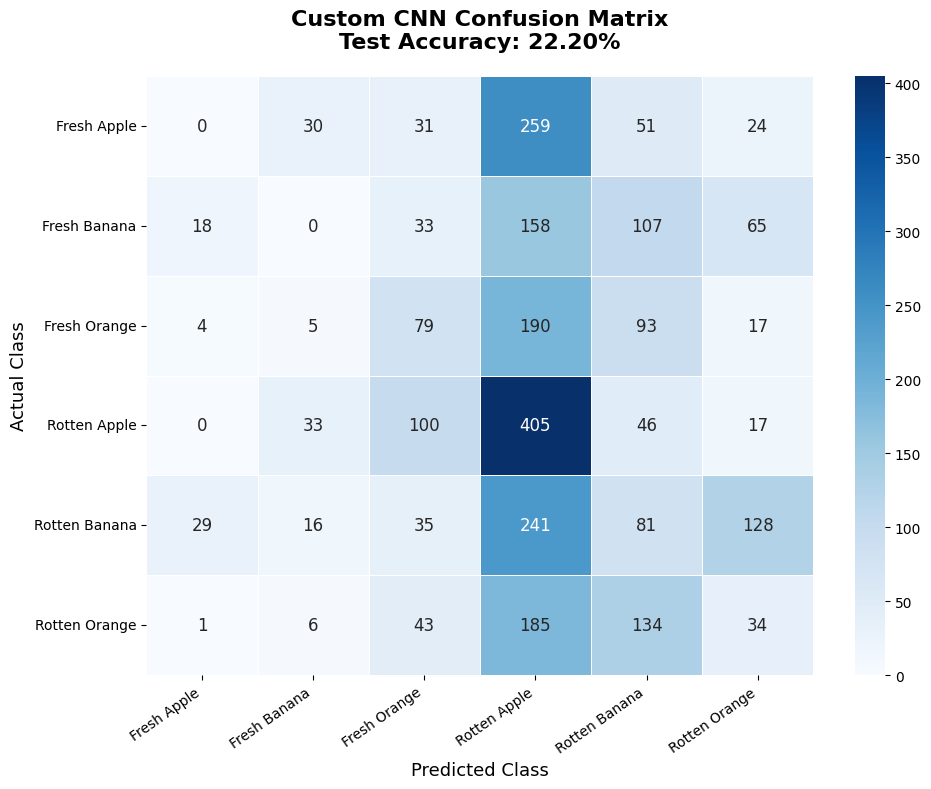

Confusion Matrix Generated Successfully!
Test Accuracy: 22.20%


In [37]:
# IMAGE 4: CUSTOM CNN CONFUSION MATRIX

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, accuracy_score

# Class names
class_names = [
    "Fresh Apple",
    "Fresh Banana",
    "Fresh Orange",
    "Rotten Apple",
    "Rotten Banana",
    "Rotten Orange"
]

# Get actual labels and model predictions
y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = cnn_model.predict(images, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Calculate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(6)
)

# Calculate accuracy
accuracy = accuracy_score(y_true, y_pred)

# Create figure
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 12}
)

plt.title(
    f"Custom CNN Confusion Matrix\nTest Accuracy: {accuracy*100:.2f}%",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Predicted Class", fontsize=13)
plt.ylabel("Actual Class", fontsize=13)

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

# Save image for research paper
plt.savefig(
    "custom_cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "custom_cnn_confusion_matrix.pdf",
    bbox_inches="tight"
)

plt.show()

print("Confusion Matrix Generated Successfully!")
print(f"Test Accuracy: {accuracy*100:.2f}%")

In [35]:
# Train the custom CNN before plotting curves or evaluating the test set.
history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)


NameError: name 'cnn_model' is not defined

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.savefig('accuracy_curve.png')
plt.show()

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.savefig('loss_curve.png')
plt.show()

In [ ]:
y_true = np.concatenate(
    [y for x, y in test_ds],
    axis=0
)

y_pred_probs = cnn_model.predict(test_ds)

y_pred = np.argmax(y_pred_probs, axis=1)

In [ ]:
test_loss, test_accuracy = cnn_model.evaluate(test_ds)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')

plt.savefig('confusion_matrix.png')

plt.show()

In [ ]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

In [ ]:
cnn_model.save("cnn_model.keras")

In [ ]:
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names
)

with open("classification_report.txt", "w") as f:
    f.write(report)

In [ ]:
# Garbage collection is optional; do not clear the Keras session here because
# the notebook continues with the same datasets and then builds EfficientNetB0.
import gc
gc.collect()


In [ ]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models

In [ ]:
from tensorflow.keras.applications import EfficientNetB0

base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

In [ ]:
base_model.trainable = False

efficientnet_model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(6, activation='softmax')
])

efficientnet_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history_eff = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

In [ ]:
test_loss_eff, test_acc_eff = efficientnet_model.evaluate(test_ds)

print("EfficientNetB0 Test Accuracy:", test_acc_eff)
print("EfficientNetB0 Test Loss:", test_loss_eff)

In [ ]:
y_pred_probs_eff = efficientnet_model.predict(test_ds)

y_pred_eff = np.argmax(y_pred_probs_eff, axis=1)

print(
    classification_report(
        y_true,
        y_pred_eff,
        target_names=class_names
    )
)

In [ ]:
cm_eff = confusion_matrix(y_true, y_pred_eff)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm_eff,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("EfficientNetB0 Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig("efficientnet_confusion_matrix.png")

plt.show()

In [ ]:
efficientnet_model.save("efficientnetb0_model.keras")

In [ ]:
plt.figure(figsize=(12,8))

for images, labels in train_ds.take(1):
    
    for i in range(9):
        
        ax = plt.subplot(3,3,i+1)
        
        plt.imshow(images[i].numpy().astype("uint8"))
        
        plt.title(class_names[labels[i]])
        
        plt.axis("off")

plt.tight_layout()
plt.show()

## Error analysis

In [ ]:
# Error analysis: compare both models on the same untouched test set.
# The class names are taken from the dataset folders; labels must match output indices.
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure labels and predictions correspond to the same deterministic test order.
y_true = np.concatenate([labels.numpy() for _, labels in test_ds], axis=0)
y_pred_cnn = np.argmax(cnn_model.predict(test_ds, verbose=0), axis=1)
y_pred_eff = np.argmax(efficientnet_model.predict(test_ds, verbose=0), axis=1)

def summarize_model(model_name, y_true, y_pred, class_names):
    # This binary view treats any class containing "rotten" as rotten.
    rotten_ids = [i for i, name in enumerate(class_names) if "rotten" in name.lower()]
    fresh_ids = [i for i, name in enumerate(class_names) if "fresh" in name.lower()]
    if not rotten_ids or not fresh_ids:
        raise ValueError(
            "Could not identify fresh/rotten classes from folder names. "
            f"Observed class names: {class_names}"
        )

    actual_rotten = np.isin(y_true, rotten_ids)
    predicted_rotten = np.isin(y_pred, rotten_ids)
    rotten_recall = recall_score(actual_rotten, predicted_rotten, zero_division=0)
    rotten_precision = precision_score(actual_rotten, predicted_rotten, zero_division=0)
    rotten_f1 = f1_score(actual_rotten, predicted_rotten, zero_division=0)

    false_negative_mask = actual_rotten & ~predicted_rotten
    summary = {
        "Model": model_name,
        "Test accuracy": accuracy_score(y_true, y_pred),
        "Six-class macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Rotten precision (binary)": rotten_precision,
        "Rotten recall (binary)": rotten_recall,
        "Rotten F1 (binary)": rotten_f1,
        "Rotten predicted as fresh/other (FN)": int(false_negative_mask.sum())
    }
    return summary, false_negative_mask

cnn_summary, cnn_fn_mask = summarize_model("Custom CNN", y_true, y_pred_cnn, class_names)
eff_summary, eff_fn_mask = summarize_model("EfficientNetB0", y_true, y_pred_eff, class_names)

comparison_df = pd.DataFrame([cnn_summary, eff_summary])
display(comparison_df.style.format({
    "Test accuracy": "{:.4f}",
    "Six-class macro F1": "{:.4f}",
    "Rotten precision (binary)": "{:.4f}",
    "Rotten recall (binary)": "{:.4f}",
    "Rotten F1 (binary)": "{:.4f}"
}))

print("\nCustom CNN classification report:")
print(classification_report(y_true, y_pred_cnn, target_names=class_names, zero_division=0))
print("\nEfficientNetB0 classification report:")
print(classification_report(y_true, y_pred_eff, target_names=class_names, zero_division=0))

# Per-class confusion matrices make common confusions visible.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, predictions, title in [
    (axes[0], y_pred_cnn, "Custom CNN — test confusion matrix"),
    (axes[1], y_pred_eff, "EfficientNetB0 — test confusion matrix")
]:
    cm = confusion_matrix(y_true, predictions, labels=np.arange(len(class_names)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

# Display up to 6 rotten-fruit false negatives for each model.
# These are true rotten images predicted as a non-rotten class.
def show_false_negatives(predictions, mask, title, max_images=6):
    indices = np.flatnonzero(mask)[:max_images]
    print(f"{title}: {int(mask.sum())} rotten images were predicted as non-rotten.")
    if len(indices) == 0:
        print("No false negatives found in this test run.")
        return

    # Dataset order is stable because test_ds was loaded with shuffle=False.
    images_all = []
    for images, _ in test_ds:
        images_all.extend(images.numpy())
        if len(images_all) >= (indices.max() + 1):
            break

    cols = 3
    rows = int(np.ceil(len(indices) / cols))
    plt.figure(figsize=(12, 4 * rows))
    for plot_idx, sample_idx in enumerate(indices, start=1):
        plt.subplot(rows, cols, plot_idx)
        image = images_all[sample_idx]
        plt.imshow(np.clip(image / 255.0, 0, 1))
        true_name = class_names[int(y_true[sample_idx])]
        pred_name = class_names[int(predictions[sample_idx])]
        plt.title(f"True: {true_name}\nPredicted: {pred_name}")
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_false_negatives(y_pred_cnn, cnn_fn_mask, "Custom CNN — rotten-fruit false negatives")
show_false_negatives(y_pred_eff, eff_fn_mask, "EfficientNetB0 — rotten-fruit false negatives")


## Limitations

1. **Limited class and food coverage.** The task covers only the six folder labels for fresh/rotten apples, bananas, and oranges. Results should not be generalized to other foods or fruit varieties without additional testing.
2. **Visual screening only.** Predictions are based on image appearance. The model cannot establish food safety or detect invisible pathogens, toxins, chemical contamination, or internal spoilage from ordinary RGB images. A “fresh” prediction is not a food-safety certification.
3. **Dataset and domain shift.** Images from different cameras, lighting, backgrounds, storage conditions, and suppliers may produce different results. Independent external validation is needed before any real-world use.
4. **Uneven class-wise performance.** Overall accuracy can hide weak classes. Use the class-wise report, confusion matrices, and rotten-to-non-rotten false-negative counts generated above to discuss errors; do not rely on accuracy alone.
5. **Possible dataset bias and leakage.** Backgrounds or acquisition patterns may correlate with labels. Duplicate or near-duplicate images across splits can inflate performance; split integrity should be checked if unusually high scores occur.
6. **Limited output scope.** This is a six-class image classifier. It does not localize spoilage, estimate severity, identify the cause of damage, or replace expert inspection/laboratory testing.
7. **Model comparison constraints.** EfficientNetB0 uses ImageNet-pretrained features while the custom CNN is trained from scratch, so the comparison reflects these particular architectures, settings, and compute conditions—not a universal ranking of models.


## Reproducibility

- **Environment:** Run this notebook in Kaggle with the dataset attached through **Add Input**. The notebook searches `/kaggle/input` for a directory containing both `train` and `test` folders, rather than relying on a machine-specific path.
- **Data split:** The code uses an 80/20 training/validation split of the training directory with `SEED = 123`; the separate test directory is held out for final evaluation. `shuffle=False` is used for test loading so predictions align with labels and images.
- **Image processing:** RGB images are resized to 224 × 224 and loaded in batches of 32. The custom CNN uses training-time augmentation (horizontal flip, rotation, zoom, and contrast) as defined in the augmentation cell.
- **Models:** Custom CNN trained with Adam and sparse categorical cross-entropy for 15 epochs. EfficientNetB0 uses ImageNet pretrained weights, a frozen base, a global average pooling layer, dropout (0.3), a 128-unit ReLU layer, and a six-unit softmax output, trained with Adam and sparse categorical cross-entropy for 10 epochs.
- **Randomness:** Python, NumPy, and TensorFlow random seeds are set to 123. GPU availability and TensorFlow version are printed in the notebook. Exact reproducibility may still vary with hardware, TensorFlow/CUDA versions, and nondeterministic GPU operations.
- **Evaluation:** Report test accuracy, six-class macro F1, class-wise precision/recall/F1, confusion matrices, and binary rotten-fruit precision/recall/F1 plus the count of rotten images predicted as non-rotten. Use the test set only for final evaluation, not for tuning.
- **Saved artifacts:** The notebook saves `cnn_model.keras`, `efficientnetb0_model.keras`, classification reports, and confusion-matrix/curve figures in the current working directory.


## Credits and references

- **Dataset:** Sriram Reddy Kalluri, *Fruits Fresh and Rotten for Classification*, Kaggle. Dataset page: https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification. Cite the dataset author/page and check the dataset page for the applicable licence and usage terms before redistribution.
- **Transfer-learning weights:** EfficientNetB0 pretrained on ImageNet, loaded through `tf.keras.applications.EfficientNetB0(weights="imagenet", include_top=False, ...)`. Reference: Tan, M. and Le, Q. V. (2019), “EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks,” *Proceedings of ICML*. https://arxiv.org/abs/1905.11946
- **Software:** TensorFlow/Keras for data loading and model training; NumPy and pandas for data handling; scikit-learn for metrics; Matplotlib and Seaborn for visualizations.
- **Code and assistance:** Record any external repositories, tutorials, generative-AI assistance, or code adapted from others that materially contributed to the project, following your course's disclosure rules. Do not claim original authorship for code or assets that were reused.
- **Scope statement:** This project demonstrates classification of visible fresh/rotten fruit labels. It does not certify that food is safe to consume.
